# Experiment 189 · Temporal specificity and feature spread

**Complete** · Geometry and external probe results saved · ETA 0h 00m 00s

The pilot uses 4,096 arrivals, three paired seeds and one fresh mask draw per seed. All arms use the same MAE images, starting states, evaluation banks and 25% replacement replay with 25% broad history. Every eighth arrival adds four two-view pairs. The original and same-frame arms follow Experiment 188. The two filtered arms keep the 16-position gap and choose only distinct frames within the pixel-change band. They prefer the nominal clip and the eight most recent eligible pairs. When the nominal clip has no usable pair, an earlier eligible clip supplies the pair. The four clips are distinct, both frames are already available, and every slot has a true temporal partner.

Pixel change is mean absolute RGB difference on a stride-4 pixel grid, normalized to [0,1]. The band uses the 40th to 85th percentiles of valid 16-position pairs from the calibration prefix. C uses the original pair MSE and SD floor of 0.25. D also applies a squared SD shortfall below 0.40 at weight 2 and a mean squared off-diagonal covariance penalty at weight 1. Both are computed across the four clips within each view. The total auxiliary weight is 0.05.

The gate requires a mean unseen temporal-gap gain of at least 0.01 against both same-frame and original temporal controls, with both comparisons positive in at least two seeds. Cross-frame retrieval may fall by at most one percentage point, and neither bank MSE may rise by more than 0.005 against either control. Median RankMe and variance must stay above 90% and 75% of same-frame. The gate runs before the frozen probes. If both pass, the larger minimum temporal-gap gain advances. Confirmation uses 32,768 arrivals, all six seeds and two masks independent of the pilot draw. It reuses the matched same-frame and original temporal arms.

**Fixed pixel-change band:** 0.0404–0.1036. Filtered pairs stayed in the nominal clip in 59.4% of pilot slots. The anchor moved back a median of 7 frames (90th percentile 74). Mean pixel change was 0.0549 under the original rule and 0.0662 after filtering. The original used self-pairs in 16.8% of slots. C and D use identical pairs, so their contrast isolates the extra regularizer. Comparing B with C also captures the resampling needed to obtain eligible pairs.

## Geometry gate

| Treatment | Minimum gap gain | Seeds beating both | Gap | Retrieval | MSE | Spread | Pass |
| --- | --- | --- | --- | --- | --- | --- | --- |
 | filtered | -0.01949 | 0 | False | True | True | True | False | 
 | regularized | -0.13713 | 0 | False | True | True | False | False | 

**Pilot decision:** no treatment qualified.

## Paired geometry and reconstruction

| Arrivals | Comparison | Pairs | frame_cosine | cross_clip_cosine | temporal_gap | temporal_retrieval | rankme | variance | unseen | historical |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 2048 | original vs same | 3 | +0.00025 | +0.00412 | -0.00387 | -0.00080 | -0.01587 | -0.00335 | -0.00009 | -0.00008 | 
 | 2048 | filtered vs original | 3 | +0.00012 | +0.00289 | -0.00277 | +0.00080 | -0.00090 | -0.00248 | -0.00006 | -0.00012 | 
 | 2048 | regularized vs original | 3 | +0.00056 | +0.07657 | -0.07601 | -0.00681 | -0.02864 | -0.07463 | +0.00017 | +0.00028 | 
 | 2048 | filtered vs same | 3 | +0.00038 | +0.00701 | -0.00663 | +0.00000 | -0.01678 | -0.00583 | -0.00015 | -0.00020 | 
 | 2048 | regularized vs same | 3 | +0.00081 | +0.08069 | -0.07988 | -0.00761 | -0.04452 | -0.07798 | +0.00008 | +0.00021 | 
 | 2048 | regularized vs filtered | 3 | +0.00043 | +0.07368 | -0.07324 | -0.00761 | -0.02774 | -0.07215 | +0.00023 | +0.00040 | 
 | 4096 | original vs same | 3 | +0.00020 | +0.00770 | -0.00749 | +0.00240 | -0.02622 | -0.00737 | -0.00046 | -0.00041 | 
 | 4096 | filtered vs original | 3 | +0.00022 | +0.01222 | -0.01200 | +0.00401 | -0.01834 | -0.01199 | -0.00013 | -0.00033 | 
 | 4096 | regularized vs original | 3 | +0.00096 | +0.13059 | -0.12964 | +0.00681 | -0.08033 | -0.12626 | -0.00045 | -0.00154 | 
 | 4096 | filtered vs same | 3 | +0.00042 | +0.01992 | -0.01949 | +0.00641 | -0.04456 | -0.01936 | -0.00059 | -0.00074 | 
 | 4096 | regularized vs same | 3 | +0.00116 | +0.13829 | -0.13713 | +0.00921 | -0.10655 | -0.13363 | -0.00091 | -0.00196 | 
 | 4096 | regularized vs filtered | 3 | +0.00073 | +0.11837 | -0.11764 | +0.00280 | -0.06198 | -0.11427 | -0.00032 | -0.00122 | 

Reconstruction values are MSE reductions. Geometry values are treatment minus reference. The specificity gap is mean within-clip cosine minus mean cross-clip cosine.

## External frozen probes

| Arrivals | Comparison | scene (pp) | weather (pp) | lighting (pp) | pedestrian (pp) |
| --- | --- | --- | --- | --- | --- |
 | 4096 | original vs same | -0.31 | +0.62 | +0.00 | -0.00 | 
 | 4096 | filtered vs original | +0.00 | -0.31 | +0.00 | +0.21 | 
 | 4096 | regularized vs original | -0.99 | +0.31 | +0.00 | +1.25 | 
 | 4096 | filtered vs same | -0.31 | +0.31 | +0.00 | +0.21 | 
 | 4096 | regularized vs same | -1.30 | +0.93 | +0.00 | +1.25 | 
 | 4096 | regularized vs filtered | -0.99 | +0.62 | +0.00 | +1.04 | 

The table uses the existing full-fit final-layer linear readout. All three layers and both readers are saved in the run JSON. These labels enter neither training nor the gate.

| Seed | Draw | Arm | Arrivals | Train time |
| --- | --- | --- | --- | --- |
 | 2029 | 0 | same | 4096 | 0h 00m 35s | 
 | 2029 | 0 | original | 4096 | 0h 00m 34s | 
 | 2029 | 0 | filtered | 4096 | 0h 00m 35s | 
 | 2029 | 0 | regularized | 4096 | 0h 00m 35s | 
 | 2031 | 0 | same | 4096 | 0h 00m 35s | 
 | 2031 | 0 | original | 4096 | 0h 00m 35s | 
 | 2031 | 0 | filtered | 4096 | 0h 00m 35s | 
 | 2031 | 0 | regularized | 4096 | 0h 00m 35s | 
 | 2034 | 0 | same | 4096 | 0h 00m 35s | 
 | 2034 | 0 | original | 4096 | 0h 00m 35s | 
 | 2034 | 0 | filtered | 4096 | 0h 00m 35s | 
 | 2034 | 0 | regularized | 4096 | 0h 00m 35s | 

In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-temporal-mechanism')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


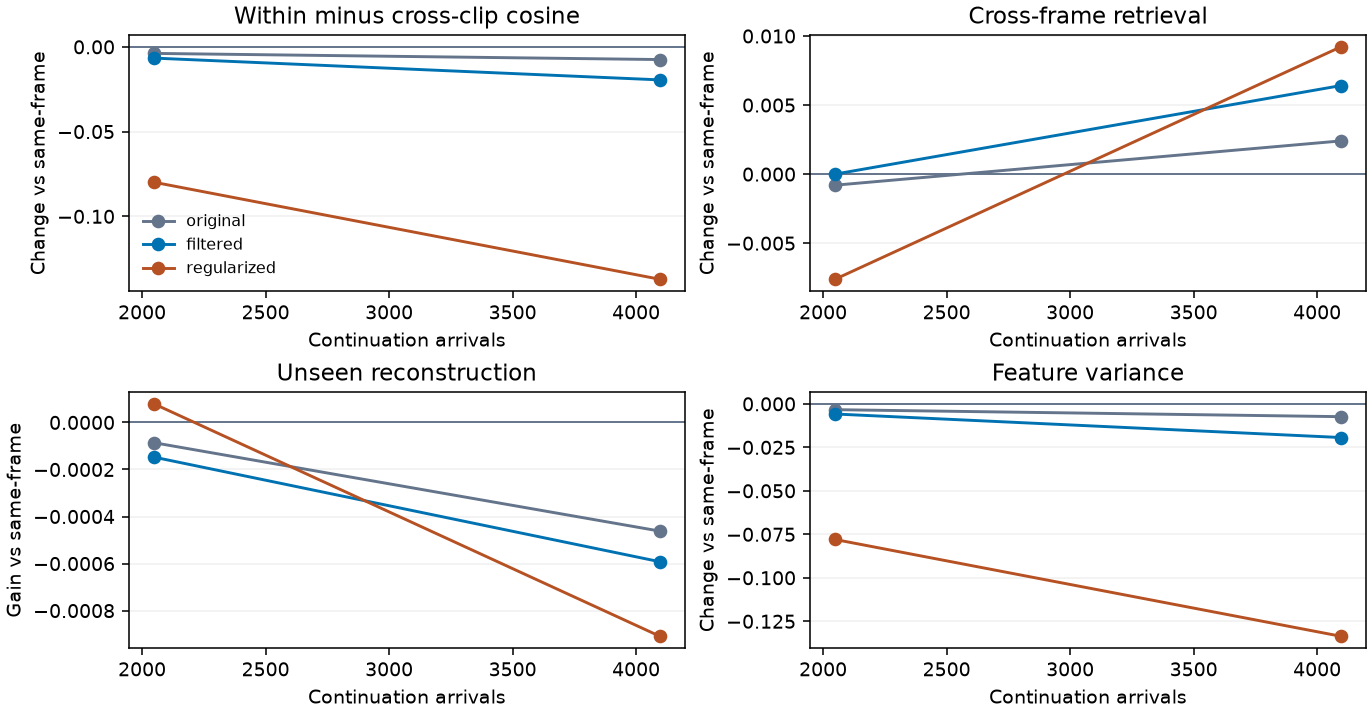